# AME 5053 — Principles of Natural Language Processing Lab
## Practical: Text classification using RNN, LSTM and GRU

**Practice notebook**

### What you will learn
By the end of this practical, you should be able to:

1. Prepare short sentences as sequences of token IDs and word embeddings.
2. Trace how **one recurrent network** produces a representation for classifying a sentence.
3. Train and compare three recurrent layers: **vanilla RNN, LSTM and GRU**.
 **question for exam**. Test the effect of word order and negation, and identify model mistakes.
5. Explain why a recurrent encoder–decoder uses **two recurrent networks** rather than one.


This lab uses a small **synthetic** feedback dataset so that training is quick and every label can be checked. It is a learning exercise, not a benchmark of real-world sentiment analysis.


## 1. Connect this lab to the earlier theory

In Unit 2, you represented words and documents numerically. A word embedding gives each token a **vector**, but it does not itself process a sentence in order.

In Unit 3.1, a recurrent network reads these vectors **one after another**. At time $t$, it combines the current input $x_t$ with its previous hidden state $h_{t-1}$ to produce $h_t$.

A standard vanilla RNN can be expressed as:

$$h_t = \tanh(W_x x_t + W_h h_{t-1}+b)$$

For our classification task the pipeline is:

**Sentence → token IDs → embedding vectors → ONE RNN/LSTM/GRU → final relevant hidden state → positive/negative prediction**

An LSTM or GRU changes the **internal recurrent cell** by adding gates. The classification pipeline remains the same.

**Connection to Unit 3.2:** There, the **encoder** recurrent network reads the source sentence and a **second**, separately parameterised **decoder** recurrent network generates an output sequence. We do not need a decoder in this lab because we predict just *one class*, not another sentence.


## 2. Setup

Run the cells from top to bottom. Google Colab normally includes PyTorch; no separate dataset download is needed. A random seed makes runs more repeatable, although results can still differ slightly between computers.


In [1]:
import random
import re
from collections import Counter

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)  # keeps this small CPU exercise responsive
DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.11.0+cpu
Device: cpu


## 3. A small, labelled feedback dataset

We create short service reviews using combinations of nouns, adjectives and sentence patterns. The **teaching rule** is simple:

- Positive adjective without *not* → positive.
- Negative adjective without *not* → negative.
- The word *not* reverses the assigned label.

For example, *"the delivery was great"* is positive, but *"the delivery was not great"* is negative. Real language is subtler: *not bad* does not always mean exactly the same as *good*. Our generated labels are deliberately simplified.

We split sentences into **training**, **validation** and **test** sets. The training data are used to fit weights; validation helps compare models; the test set is checked after training. Because the same vocabulary and sentence patterns appear across splits, these numbers **do not measure generalisation to real customer reviews**.


In [2]:
things = ["service", "delivery", "product", "support",
          "website", "booking", "experience", "response"]
positive_words = ["good", "great", "excellent", "reliable"]
negative_words = ["bad", "poor", "terrible", "disappointing"]

patterns = [
    "the {thing} was {word}",
    "i think the {thing} was {word}",
    "overall the {thing} was {word}",
    "the {thing} seemed really {word}",
    "the {thing} was not {word}",
    "i think the {thing} was not {word}",
    "overall the {thing} was not very {word}",
    "the {thing} was definitely not {word}",
]

examples = []  # each item: (sentence, label), with 1=positive and 0=negative
for thing in things:
    for word in positive_words + negative_words:
        for pattern in patterns:
            sentence = pattern.format(thing=thing, word=word)
            is_positive = word in positive_words
            if " not " in sentence:
                is_positive = not is_positive
            examples.append((sentence, int(is_positive)))

random.shuffle(examples)
n = len(examples)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
train_items = examples[:n_train]
val_items = examples[n_train:n_train + n_val]
test_items = examples[n_train + n_val:]

print("Total:", n, "| Train:", len(train_items),
      "| Validation:", len(val_items), "| Test:", len(test_items))
print("Some training examples:")
for text, label in train_items[:5]:
    print(f"  {text:<48} label={label}")

Total: 512 | Train: 358 | Validation: 76 | Test: 78
Some training examples:
  i think the support was bad                      label=0
  i think the support was not excellent            label=0
  the booking was reliable                         label=1
  the delivery was definitely not disappointing    label=1
  the response was definitely not good             label=0


**Practice 1 — Read the data.** Find two sentences in the generated dataset that differ only by the word *not*. Print their labels. Do they change as intended?

In [3]:
# TODO 1: Look up these two sentences in 'examples' and print their labels.
# Suggested sentences: "the delivery was great" and "the delivery was not great"
sentence_1 = "the delivery was great"
sentence_2 = "the delivery was not great"

label_1 = next((label for s, label in examples if s == sentence_1), None)
label_2 = next((label for s, label in examples if s == sentence_2), None)

print(f"Sentence: '{sentence_1}' -> Label: {label_1}")
print(f"Sentence: '{sentence_2}' -> Label: {label_2}")


Sentence: 'the delivery was great' -> Label: 1
Sentence: 'the delivery was not great' -> Label: 0


## 4. Convert words to numbers

Neural networks cannot take Python strings directly. We first **tokenise** each sentence, then assign an integer ID to each token.

- `<PAD>` has ID 0 and fills unused positions in a batch.
- `<UNK>` has ID 1 for a word not seen in the training vocabulary.
- An **embedding layer** later turns each ID into a *trainable* vector.

For simplicity, tokenisation uses lower-case letter sequences. We build the vocabulary from the **training data only**. In this small generated dataset, nearly all test words will already be known; that is another reason not to interpret its test score as real-world performance.


In [4]:
def tokenize(sentence):
    return re.findall(r"[a-z]+", sentence.lower())

PAD_ID, UNK_ID = 0, 1
vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
for sentence, _ in train_items:
    for token in tokenize(sentence):
        if token not in vocab:
            vocab[token] = len(vocab)

def encode(sentence):
    return [vocab.get(token, UNK_ID) for token in tokenize(sentence)]

example_sentence = "the delivery was not great"
print("Sentence:", example_sentence)
print("Tokens:  ", tokenize(example_sentence))
print("IDs:     ", encode(example_sentence))
print("Vocabulary size:", len(vocab))

Sentence: the delivery was not great
Tokens:   ['the', 'delivery', 'was', 'not', 'great']
IDs:      [4, 12, 6, 8, 27]
Vocabulary size: 28


### Different sentence lengths: padding and the last *real* word

A batch contains sentences with different numbers of tokens. We pad shorter sequences to match the longest one **in that batch**. Padding is not a word and should not decide the class.

Our classifier therefore uses the hidden state at the **last real token**, not the final `<PAD>` position. This works here because all three recurrent layers process the real tokens before any trailing padding. More advanced systems may use packed sequences or masking.


In [5]:
class FeedbackDataset(Dataset):
    def __init__(self, items):
        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        sentence, label = self.items[index]
        return encode(sentence), label, sentence


def make_batch(rows):
    sequences, labels, sentences = zip(*rows)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    token_tensors = [torch.tensor(seq, dtype=torch.long) for seq in sequences]
    padded = pad_sequence(token_tensors, batch_first=True, padding_value=PAD_ID)
    return padded, lengths, torch.tensor(labels, dtype=torch.long), list(sentences)

BATCH_SIZE = 64
train_loader = DataLoader(FeedbackDataset(train_items), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=make_batch)
val_loader = DataLoader(FeedbackDataset(val_items), batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=make_batch)
test_loader = DataLoader(FeedbackDataset(test_items), batch_size=BATCH_SIZE,
                         shuffle=False, collate_fn=make_batch)

batch_ids, batch_lengths, batch_labels, batch_texts = next(iter(train_loader))
print("Token-ID batch shape:", tuple(batch_ids.shape))  # (batch, time)
print("First sentence:", batch_texts[0])
print("First row of padded IDs:", batch_ids[0].tolist())
print("Its real length:", batch_lengths[0].item())

Token-ID batch shape: (64, 7)
First sentence: the response was not excellent
First row of padded IDs: [4, 15, 6, 8, 9, 0, 0]
Its real length: 5


## 5. One classifier, three choices of recurrent cell

We build a single `TextClassifier` class. The **only architectural choice we change** is `cell_type`:

| Choice | Recurrent layer | What it remembers |
|---|---|---|
| `RNN` | `nn.RNN` | One hidden state, updated repeatedly |
| `LSTM` | `nn.LSTM` | Hidden state and separate cell state, controlled by gates |
| `GRU` | `nn.GRU` | One main recurrent state, controlled by reset/update gates |

All models use the same sequence-classification pipeline:

1. `Embedding` maps token IDs to vectors of size 16.
2. The recurrent layer produces a hidden state at each input position.
3. We select the state after the last real word.
4. A linear classifier produces **two scores** (*logits*), one per class.

The loss function `CrossEntropyLoss` later turns these scores into the appropriate learning objective. **Do not apply softmax to logits before passing them to `CrossEntropyLoss`.**


In [6]:
class TextClassifier(nn.Module):
    def __init__(self, cell_type, vocab_size, embedding_dim=16, hidden_dim=24):
        super().__init__()
        self.cell_type = cell_type
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        layer_options = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        self.recurrent = layer_options[cell_type](
            input_size=embedding_dim, hidden_size=hidden_dim, batch_first=True
        )
        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, token_ids, lengths):
        vectors = self.embedding(token_ids)      # (batch, time, 16)
        output, _ = self.recurrent(vectors)       # (batch, time, 24)
        last_real_word = lengths - 1
        last_states = output[torch.arange(output.size(0)), last_real_word]
        return self.classifier(last_states)       # (batch, 2) raw class scores


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters()
               if parameter.requires_grad)

for cell_type in ["RNN", "LSTM", "GRU"]:
    model = TextClassifier(cell_type, vocab_size=len(vocab))
    scores = model(batch_ids, batch_lengths)
    print(f"{cell_type:>4}: output shape={tuple(scores.shape)}; "
          f"trainable parameters={count_parameters(model):,}")

 RNN: output shape=(64, 2); trainable parameters=1,506
LSTM: output shape=(64, 2); trainable parameters=4,530
 GRU: output shape=(64, 2); trainable parameters=3,522


**Interpret the printed shapes:** If a batch has $B$ sentences and each sentence receives two class scores, the output shape is $(B,2)$. The embedding/recurrent layers have different internal sizes. The parameter counts of RNN, LSTM and GRU differ even when their input and hidden sizes are equal; **more parameters does not guarantee better accuracy**.


## 6. Train the three models

Training follows exactly the same logic for each recurrent layer:

**Forward pass → class scores → loss → backward gradients → update weights.**

For targets $y_i$ and predicted class probabilities $p(y_i\mid x_i)$, the average cross-entropy is:

$$L=-\frac{1}{N}\sum_{i=1}^{N}\log p(y_i\mid x_i)$$

We do not have to compute the derivatives by hand; PyTorch performs backpropagation through time. We use Adam to update weights and a small gradient-clipping step to avoid unusually large gradients.

**Fair comparison:** same train/validation/test sets, embedding size, hidden size, number of epochs and optimiser settings. Cell structures and parameter counts still differ, so this is a classroom comparison, not a controlled research benchmark.


In [7]:
loss_function = nn.CrossEntropyLoss()
EPOCHS = 8
LEARNING_RATE = 0.01

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0
    for ids, lengths, labels, _ in loader:
        logits = model(ids, lengths)
        loss = loss_function(logits, labels)
        total_loss += loss.item() * len(labels)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_count += len(labels)
    return total_loss / total_count, total_correct / total_count


def train_model(cell_type):
    torch.manual_seed(SEED)
    model = TextClassifier(cell_type, vocab_size=len(vocab)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for ids, lengths, labels, _ in train_loader:
            optimizer.zero_grad()
            logits = model(ids, lengths)
            loss = loss_function(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        train_loss, train_accuracy = evaluate(model, train_loader)
        val_loss, val_accuracy = evaluate(model, val_loader)
        history.append((train_loss, train_accuracy, val_loss, val_accuracy))
        print(f"{cell_type:4s} | epoch {epoch:2d} | "
              f"train acc {train_accuracy:.1%} | validation acc {val_accuracy:.1%}")
    return model, history

trained_models = {}
histories = {}
for name in ["RNN", "LSTM", "GRU"]:
    print("\nTraining", name)
    trained_models[name], histories[name] = train_model(name)


Training RNN
RNN  | epoch  1 | train acc 57.3% | validation acc 53.9%
RNN  | epoch  2 | train acc 67.9% | validation acc 64.5%
RNN  | epoch  3 | train acc 86.6% | validation acc 85.5%
RNN  | epoch  4 | train acc 94.4% | validation acc 97.4%
RNN  | epoch  5 | train acc 100.0% | validation acc 100.0%
RNN  | epoch  6 | train acc 100.0% | validation acc 100.0%
RNN  | epoch  7 | train acc 100.0% | validation acc 100.0%
RNN  | epoch  8 | train acc 100.0% | validation acc 100.0%

Training LSTM
LSTM | epoch  1 | train acc 57.0% | validation acc 63.2%
LSTM | epoch  2 | train acc 80.2% | validation acc 73.7%
LSTM | epoch  3 | train acc 96.9% | validation acc 97.4%
LSTM | epoch  4 | train acc 100.0% | validation acc 100.0%
LSTM | epoch  5 | train acc 100.0% | validation acc 100.0%
LSTM | epoch  6 | train acc 100.0% | validation acc 100.0%
LSTM | epoch  7 | train acc 100.0% | validation acc 100.0%
LSTM | epoch  8 | train acc 100.0% | validation acc 100.0%

Training GRU
GRU  | epoch  1 | train acc

## 7. Compare the results

Accuracy is the number of correctly classified sentences divided by the number examined:

$$\mathrm{Accuracy}=\frac{\text{correct predictions}}{\text{all predictions}}$$

The test set is used only after the training above. Results can vary with initialization and the generated data; no fixed ordering such as "LSTM always beats RNN" should be inferred.


Model      Parameters     Val acc    Test acc
RNN             1,506      100.0%      100.0%
LSTM            4,530      100.0%      100.0%
GRU             3,522      100.0%      100.0%
Model with highest validation accuracy: RNN


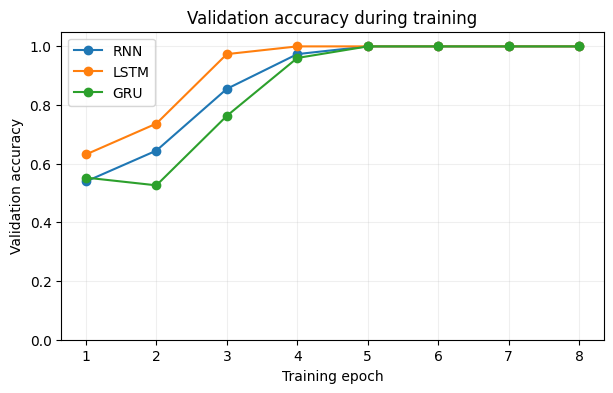

In [8]:
print(f"{'Model':<8}{'Parameters':>13}{'Val acc':>12}{'Test acc':>12}")
results = {}
for name, model in trained_models.items():
    _, val_acc = evaluate(model, val_loader)
    _, test_acc = evaluate(model, test_loader)
    results[name] = (val_acc, test_acc)
    print(f"{name:<8}{count_parameters(model):>13,}{val_acc:>12.1%}{test_acc:>12.1%}")

best_name = max(results, key=lambda name: results[name][0])
print("Model with highest validation accuracy:", best_name)

plt.figure(figsize=(7, 4))
for name, history in histories.items():
    plt.plot(range(1, EPOCHS + 1), [row[3] for row in history],
             marker='o', label=name)
plt.xlabel("Training epoch")
plt.ylabel("Validation accuracy")
plt.ylim(0, 1.05)
plt.title("Validation accuracy during training")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### What should you observe?

- The models may learn at different speeds.
- Gating helps an LSTM or GRU control its state, especially for longer dependencies, but **does not ensure** a higher score on every task.
- On short, rule-based sentences, even a simple RNN may perform well.
- If accuracy is weak, inspect training and test examples before claiming the architecture is unsuitable.

**Caution:** This dataset repeats a few language patterns, so high test accuracy can coexist with poor performance on naturally written reviews.


## 8. Predict a new sentence

`predict_sentence` applies the same tokenisation and vocabulary, then asks one trained model for its two class scores. Softmax converts these logits to two probabilities that add to 1. The reported probability is **not** a reliable confidence estimate outside our toy data distribution.


In [9]:
@torch.no_grad()
def predict_sentence(model, sentence):
    model.eval()
    ids = encode(sentence)
    if not ids:
        raise ValueError("Please enter a sentence containing words.")
    token_tensor = torch.tensor([ids], dtype=torch.long)
    length_tensor = torch.tensor([len(ids)], dtype=torch.long)
    logits = model(token_tensor, length_tensor)
    probs = torch.softmax(logits, dim=1)[0]
    predicted = int(probs.argmax())
    label_name = "positive" if predicted == 1 else "negative"
    return label_name, float(probs[predicted])

sample_sentences = [
    "the support was excellent",
    "the support was not excellent",
    "the booking was terrible",
    "the booking was not terrible",
]
for sentence in sample_sentences:
    label, score = predict_sentence(trained_models[best_name], sentence)
    print(f"{sentence:<40} -> {label:<8} (model score {score:.2f})")

the support was excellent                -> positive (model score 0.98)
the support was not excellent            -> negative (model score 0.98)
the booking was terrible                 -> negative (model score 0.97)
the booking was not terrible             -> positive (model score 0.94)


**Practice 2 — Explore word order and negation.** Use `predict_sentence` on any two additional sentences that differ by adding *not*. Compare RNN, LSTM and GRU outputs. Do not assume every result will be correct.

In [10]:
# TODO 2: Create two new sentences, then make a prediction with each of the three models.
sentence_1 = "the product was great"
sentence_2 = "the product was not great"

for name, model in trained_models.items():
    label_1, score_1 = predict_sentence(model, sentence_1)
    label_2, score_2 = predict_sentence(model, sentence_2)
    print(f"{name:4s} | '{sentence_1}' -> {label_1} ({score_1:.2f})")
    print(f"{name:4s} | '{sentence_2}' -> {label_2} ({score_2:.2f})")
    print("-" * 50)


RNN  | 'the product was great' -> positive (0.95)
RNN  | 'the product was not great' -> negative (0.92)
--------------------------------------------------
LSTM | 'the product was great' -> positive (1.00)
LSTM | 'the product was not great' -> negative (1.00)
--------------------------------------------------
GRU  | 'the product was great' -> positive (1.00)
GRU  | 'the product was not great' -> negative (1.00)
--------------------------------------------------


In [15]:
# TODO 4: Compare token IDs and predictions for two sentences with unseen adjectives.
sentence_unseen_1 = "the service was amazing"
sentence_unseen_2 = "the service was horrible"

ids_1 = encode(sentence_unseen_1)
ids_2 = encode(sentence_unseen_2)

print(f"Tokens 1: {tokenize(sentence_unseen_1)} -> IDs: {ids_1}")
print(f"Tokens 2: {tokenize(sentence_unseen_2)} -> IDs: {ids_2}")
print(f"Are IDs identical? {ids_1 == ids_2}")

pred_1, score_1 = predict_sentence(trained_models[best_name], sentence_unseen_1)
pred_2, score_2 = predict_sentence(trained_models[best_name], sentence_unseen_2)

print(f"Prediction for '{sentence_unseen_1}': {pred_1} ({score_1:.2f})")
print(f"Prediction for '{sentence_unseen_2}': {pred_2} ({score_2:.2f})")

Tokens 1: ['the', 'service', 'was', 'amazing'] -> IDs: [4, 26, 6, 1]
Tokens 2: ['the', 'service', 'was', 'horrible'] -> IDs: [4, 26, 6, 1]
Are IDs identical? True
Prediction for 'the service was amazing': negative (0.93)
Prediction for 'the service was horrible': negative (0.93)
